# 03 · Cluster di pazienti con selezione incrementale delle feature

**Idea.** Trovare gruppi di pazienti omogenei (cluster) dentro i quali la predizione del target sia più accurata che sul totale, scegliendo *quali feature usare per formare i cluster* e poi *quali feature usare per predire dentro ciascun cluster*.

**Pipeline** (tutto ciò che è appreso usa solo il train; validation serve per scegliere, test solo alla fine):

1. **Scelta delle feature per il clustering**
   - *eliminazione all'indietro*: si parte da tutte le feature e si toglie a ogni passo quella che migliora di più la qualità dei cluster (silhouette + stabilità);
   - *sparse k-means* (Witten & Tibshirani): assegna un peso a ogni feature e porta a zero quelle inutili.
2. **Clustering finale** e assegnazione di train/validation/test ai cluster.
3. **I cluster differiscono per l'esito?** Prevalenza del target e di ogni condizione per cluster.
4. **Predizione dentro ogni cluster** con eliminazione all'indietro delle feature predittive (CV raggruppata per paziente sul solo train del cluster), confronto con il modello globale **sugli stessi pazienti**.
5. **Soglia di rumore**: quanto bene "funziona" il miglior cluster anche con etichette mescolate a caso? Serve per non vendere come risultato un colpo di fortuna.

La clusterizzazione è non supervisionata: non conosce l'esito. Un cluster ben separato non implica che dentro ci sia predicibilità. Per questo il punto 4 è il test che conta.

In [1]:
#@title Setup comune: configurazione, caricamento dati, funzioni di utilità
import os, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

# ===================== CONFIGURAZIONE =====================
DATA_DIR = Path(os.environ.get("ECHONEXT_DIR", "/home/idalab/Desktop/Teo/physionet.org/files/echonext/1.1.1"))   # cartella con lo zip (o i file già estratti)
OUT_DIR  = Path(os.environ.get("ECHONEXT_OUT", str(Path.home() / "echonext_results")))  # dove salvare i risultati
SEED = 42
DEBUG_N = int(os.environ.get("ECHONEXT_DEBUG_N", "0")) or None  # es. 3000 = prova rapida con 3000 righe per split
RUN_FINAL_TEST = False   # lasciare False finché pipeline e scelte non sono congelate (vedi ultima cella)
TARGET = "shd_moderate_or_greater_flag"
# ==========================================================

def locate_dataset(root):
    """Trova il CSV dei metadati (anche in sottocartelle, anche .csv.gz); se c'è solo uno zip lo estrae in <root>/extracted.
    Se non trova nulla, stampa il contenuto della cartella per capire cosa manca."""
    import zipfile
    root = Path(root).expanduser()
    if not root.exists(): raise FileNotFoundError(f"Cartella non trovata: {root}")
    def find_csv(base):
        c = [p for p in base.rglob("*") if p.is_file() and "metadata" in p.name.lower() and p.name.lower().endswith((".csv", ".csv.gz"))]
        return sorted(c, key=lambda p: ("100k" not in p.name.lower(), len(str(p))))
    hits = find_csv(root)
    if hits: return hits[0]
    target = root / "extracted"
    for z in sorted(root.rglob("*.zip")):
        with zipfile.ZipFile(z) as zf:
            if any("metadata" in n.lower() and ".csv" in n.lower() for n in zf.namelist()):
                print(f"estraggo {z.name} in {target} ... (può richiedere minuti)"); zf.extractall(target); break
    hits = find_csv(target) if target.exists() else []
    if hits: return hits[0]
    files = sorted(p for p in root.rglob("*") if p.is_file())
    listing = "\n".join(f"  {p.relative_to(root)}  ({p.stat().st_size / 1e6:.2f} MB)" for p in files[:30])
    raise FileNotFoundError(f"Nessun CSV di metadata in {root}.\nContenuto trovato ({len(files)} file):\n{listing or '  (nessun file)'}\n"
                            "Se vedi solo index.html o file di pochi KB il download non è andato a buon fine (credenziali o DUA non firmato); "
                            "se i file stanno altrove, punta DATA_DIR alla cartella giusta.")

META_PATH = locate_dataset(DATA_DIR)
DATA_DIR = META_PATH.parent
print("dati in:", DATA_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)

# Feature ECG ammesse come INPUT dei modelli (misure automatiche dell'ECG + demografia)
ECG_FEATURES = ["sex", "ventricular_rate", "atrial_rate", "pr_interval", "qrs_duration", "qt_corrected", "age_at_ecg"]
# Etichette binarie derivate dall'ecocardiogramma (possibili TARGET)
FLAG_COLS = ["shd_moderate_or_greater_flag", "lvef_lte_45_flag", "lvwt_gte_13_flag",
             "aortic_stenosis_moderate_or_greater_flag", "aortic_regurgitation_moderate_or_greater_flag",
             "mitral_regurgitation_moderate_or_greater_flag", "tricuspid_regurgitation_moderate_or_greater_flag",
             "pulmonary_regurgitation_moderate_or_greater_flag", "rv_systolic_dysfunction_moderate_or_greater_flag",
             "pericardial_effusion_moderate_large_flag", "pasp_gte_45_flag", "tr_max_gte_32_flag"]
# Colonne derivate dall'eco: MAI usarle come input (leakage del target)
ECHO_ONLY_COLS = ["aortic_stenosis_value", "aortic_regurgitation_value", "mitral_regurgitation_value",
                  "tricuspid_regurgitation_value", "pulmonary_regurgitation_value", "rv_systolic_function_value",
                  "pericardial_effusion_value", "ivs_measurement", "lvpw_measurement", "pasp_value",
                  "tr_max_velocity_value", "lvef_value"] + FLAG_COLS
assert not set(ECG_FEATURES) & set(ECHO_ONLY_COLS), "leakage: feature eco tra gli input"

# ---------- caricamento metadata ----------
meta = pd.read_csv(META_PATH)
meta["sex"] = meta["sex"].astype(str).str.lower().map({"male": 1, "female": 0, "m": 1, "f": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0})
assert meta["sex"].notna().mean() > 0.9, "colonna sex non interpretata: controlla i valori"
# l'ordine delle righe del CSV corrisponde all'ordine dei file .npy di ciascuno split
meta["row_in_split"] = meta.groupby("split").cumcount()
if DEBUG_N:
    meta = meta.groupby("split").head(DEBUG_N)
train, val, test = (meta[meta.split == s].copy() for s in ("train", "val", "test"))
print(f"train={len(train):,}  val={len(val):,}  test={len(test):,}  (no_split={int((meta.split=='no_split').sum()):,})")

# ---------- metriche ----------
from sklearn.metrics import roc_auc_score, average_precision_score, mean_absolute_error, r2_score

def safe_auc(y, p):
    y = np.asarray(y)
    return roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan

def boot_ci(y, p, fn=safe_auc, n=300, seed=0):
    """Intervallo di confidenza al 95% per bootstrap sulle righe (val/test hanno 1 ECG per paziente)."""
    rng = np.random.default_rng(seed); y = np.asarray(y); p = np.asarray(p); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); v = fn(y[i], p[i])
        if not np.isnan(v): vals.append(v)
    return (np.percentile(vals, 2.5), np.percentile(vals, 97.5)) if vals else (np.nan, np.nan)

def fmt_auc(y, p):
    lo, hi = boot_ci(y, p)
    return safe_auc(y, p), lo, hi

# ---------- dati e modelli ----------
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict

def get_xy(df, target, features=ECG_FEATURES):
    """Restituisce X, y, df filtrato (righe con target mancante escluse)."""
    d = df.dropna(subset=[target])
    y = d[target].values
    y = y.astype(int) if target in FLAG_COLS else y.astype(float)
    return d[list(features)].astype(float), y, d

def model_zoo(seed=SEED):
    """Più modelli da confrontare: lineare, lineare sparso (Lasso), foresta, boosting, rete densa (MLP)."""
    imp = lambda: SimpleImputer(strategy="median", add_indicator=True)  # l'indicatore cattura "PR/atrial rate mancante" (es. fibrillazione)
    return {
        "logreg": make_pipeline(imp(), StandardScaler(), LogisticRegression(max_iter=2000, C=1.0)),
        "lasso_logreg": make_pipeline(imp(), StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=0.1)),
        "random_forest": make_pipeline(imp(), RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=seed)),
        "hist_gb": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=250, random_state=seed),
        "mlp_dense": make_pipeline(imp(), StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=200, random_state=seed)),
    }

def eval_models(Xtr, ytr, Xva, yva, models=None):
    """Addestra su train, valuta su val. Ritorna tabella AUROC (con IC95%) e predizioni."""
    rows, preds = [], {}
    for name, m in (models or model_zoo()).items():
        t0 = time.time(); m.fit(Xtr, ytr); p = m.predict_proba(Xva)[:, 1]
        a, lo, hi = fmt_auc(yva, p)
        rows.append(dict(model=name, AUROC=a, CI_lo=lo, CI_hi=hi, AUPRC=average_precision_score(yva, p),
                         prev_val=float(np.mean(yva)), n_val=len(yva), sec=round(time.time() - t0, 1)))
        preds[name] = p
    return pd.DataFrame(rows).sort_values("AUROC", ascending=False).reset_index(drop=True), preds

def oof_proba(model, X, y, groups, n_splits=5):
    """Predizioni out-of-fold con CV raggruppata per paziente (nessun paziente in train e test dello stesso fold)."""
    return cross_val_predict(model, X, y, groups=groups, cv=GroupKFold(n_splits), method="predict_proba")[:, 1]

def add_groups(df):
    """Aggiunge fasce di QRS ed età, usate per stratificare."""
    d = df.copy()
    d["qrs_bin"] = pd.cut(d.qrs_duration, [0, 100, 120, 10000], labels=["<100", "100-119", ">=120"], right=False).astype(object)
    d["age_bin"] = pd.cut(d.age_at_ecg, [0, 50, 65, 75, 200], labels=["<50", "50-64", "65-74", ">=75"], right=False).astype(object)
    return d

dati in: /home/idalab/Desktop/Teo/physionet.org/files/echonext/1.1.1
train=72,475  val=4,626  test=5,442  (no_split=17,457)


## 1 · Configurazione e feature

Per default si usano le 7 feature tabulari. Con `USE_WAVE_FEATURES = True` si aggiungono 36 descrittori semplici calcolati dalle forme d'onda (deviazione standard, ampiezza picco-picco, variazione media per derivazione), il che richiede i file `.npy` delle forme d'onda e molto più tempo di lettura. L'ordine delle derivazioni nell'array è assunto standard (I, II, III, aVR, aVL, aVF, V1-V6): verifica con il repository IntroECG se vuoi interpretare i nomi.

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy import stats

USE_WAVE_FEATURES = False
N_CLUSTER = 20000          # ECG (uno per paziente) usati per apprendere i cluster
N_SEARCH = 8000            # sottocampione per la ricerca delle feature (più veloce)
K_LIST = [3, 4, 5]         # numeri di cluster da provare
PRED_TARGET = TARGET       # esito da predire dentro i cluster (es. "lvef_lte_45_flag")
PRED_FEATURES = ECG_FEATURES

LEADS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
WAVE_NAMES = [f"{s}_{l}" for s in ("std", "ptp", "absdiff") for l in LEADS]

def wave_features(split_name, rows, chunk=500):
    W = np.load(DATA_DIR / f"EchoNext_{split_name}_waveforms.npy", mmap_mode="r")
    out = []
    for i in range(0, len(rows), chunk):
        x = np.asarray(W[rows[i:i + chunk], 0])                      # (n, 2500, 12)
        out.append(np.concatenate([x.std(1), x.max(1) - x.min(1), np.abs(np.diff(x, axis=1)).mean(1)], axis=1))
    return pd.DataFrame(np.vstack(out), columns=WAVE_NAMES)

def feature_frame(df, split_name, need_wave):
    F = df[ECG_FEATURES].reset_index(drop=True).astype(float)
    if need_wave:
        F = pd.concat([F, wave_features(split_name, df.row_in_split.values)], axis=1)
    return F

pool = train.drop_duplicates("patient_key").sample(min(N_CLUSTER, train.patient_key.nunique()), random_state=SEED).sort_values("row_in_split")
F_pool = feature_frame(pool, "train", USE_WAVE_FEATURES)
if USE_WAVE_FEATURES:       # elimina feature quasi duplicate (|corr| > 0.95)
    c = F_pool.corr().abs(); drop = set()
    for i, a in enumerate(c.columns):
        for b in c.columns[i + 1:]:
            if b not in drop and c.loc[a, b] > 0.95: drop.add(b)
    F_pool = F_pool.drop(columns=list(drop)); print("feature scartate perché ridondanti:", len(drop))
names = list(F_pool.columns)
def prep_fit(F):
    imp, sc = SimpleImputer(strategy="median"), StandardScaler()
    Z = np.clip(sc.fit_transform(imp.fit_transform(F)), -4, 4)    # clip: evita che pochi outlier dominino i cluster
    return imp, sc, Z
imp0, sc0, Zpool = prep_fit(F_pool)
rng = np.random.default_rng(SEED)
sub = rng.choice(len(Zpool), min(N_SEARCH, len(Zpool)), replace=False); Zs = Zpool[sub]
print(f"pool cluster: {Zpool.shape}  | sottocampione ricerca: {Zs.shape}")

pool cluster: (20000, 7)  | sottocampione ricerca: (8000, 7)


## 2 · Eliminazione all'indietro delle feature

Per ogni numero di cluster `k` si parte da tutte le feature e si elimina, un passo alla volta, quella la cui rimozione dà il punteggio migliore. Il **punteggio** è la media di:
- *silhouette* (quanto sono compatti e separati i cluster);
- *stabilità* (ARI tra due clusterizzazioni fatte su metà dati diverse: se i cluster cambiano a ogni ricampionamento non sono affidabili).

Attenzione: la silhouette tende a salire quando si tolgono dimensioni, qualunque esse siano. Per questo si guarda anche la stabilità e si impone un minimo di 3 feature nella scelta automatica. Il punteggio è un'euristica, non una verità.

fatto in 15s


,k,n_feats,removed,silhouette,stability,score
0,3,7,NaN,0.206,0.215,0.211
1,3,6,ventricular_rate,0.245,0.983,0.614
2,3,5,age_at_ecg,0.314,0.991,0.653
3,3,4,pr_interval,0.404,0.986,0.695
4,3,3,qt_corrected,0.535,0.995,0.765
5,3,2,qrs_duration,0.750,0.999,0.874
6,4,7,NaN,0.204,0.951,0.577
7,4,6,pr_interval,0.245,0.964,0.605
8,4,5,age_at_ecg,0.326,0.968,0.647
9,4,4,qt_corrected,0.413,0.974,0.694


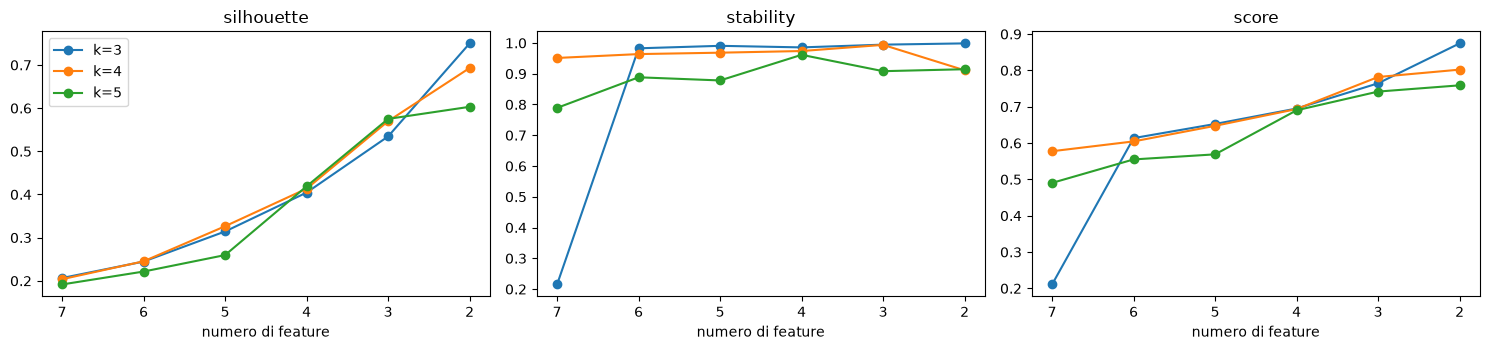

In [3]:
def km_fit(Z, k, seed=0): return KMeans(k, n_init=2, random_state=seed).fit(Z)

def sil_stab(Z, cols, k, n_eval=3000, n_rep=3, seed=0):
    r = np.random.default_rng(seed); Zc = Z[:, cols]
    ev = r.choice(len(Zc), min(n_eval, len(Zc)), replace=False)
    sil = silhouette_score(Zc[ev], km_fit(Zc, k).predict(Zc[ev]))
    aris = []
    for i in range(n_rep):
        perm = r.permutation(len(Zc)); a, b = perm[:len(Zc) // 2], perm[len(Zc) // 2:]
        aris.append(adjusted_rand_score(km_fit(Zc[a], k, i).predict(Zc[ev]), km_fit(Zc[b], k, i + 100).predict(Zc[ev])))
    return float(sil), float(np.mean(aris))

def backward_path(Z, names, k, min_feats=2):
    cols = list(range(Z.shape[1])); path = []
    s, st = sil_stab(Z, cols, k)
    path.append(dict(k=k, n_feats=len(cols), removed=None, silhouette=s, stability=st, score=(s + st) / 2, features=[names[c] for c in cols]))
    while len(cols) > min_feats:
        best = None
        for c in cols:
            s, st = sil_stab(Z, [x for x in cols if x != c], k)
            if best is None or (s + st) / 2 > best[0]: best = ((s + st) / 2, c, s, st)
        sc, c, s, st = best; cols.remove(c)
        path.append(dict(k=k, n_feats=len(cols), removed=names[c], silhouette=s, stability=st, score=sc, features=[names[x] for x in cols]))
    return path

t0 = time.time()
bw = pd.DataFrame([row for k in K_LIST for row in backward_path(Zs, names, k)])
print(f"fatto in {time.time() - t0:.0f}s")
bw.drop(columns="features").to_csv(OUT_DIR / "03_backward_path.csv", index=False)
display(bw.drop(columns="features").round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for k, g in bw.groupby("k"):
    for a, col in zip(ax, ["silhouette", "stability", "score"]): a.plot(g.n_feats, g[col], marker="o", label=f"k={k}"); a.set_title(col); a.set_xlabel("numero di feature"); a.invert_xaxis()
ax[0].legend(); plt.tight_layout(); plt.show()

## 3 · Sparse k-means

Alternativa che sceglie cluster e feature **insieme**. Il parametro `s` controlla la sparsità: valori bassi tengono poche feature, valori vicini a √p le tengono quasi tutte. Si provano più valori di `s` e per ciascuno si riportano feature attive, silhouette e stabilità.

In [4]:
def _soft(a, d): return np.sign(a) * np.maximum(np.abs(a) - d, 0)
def update_w(a, s):
    a = np.maximum(a, 0); nrm = np.linalg.norm(a)
    w = a / nrm if nrm > 0 else np.ones_like(a) / np.sqrt(len(a))
    if w.sum() <= s: return w
    lo, hi = 0.0, a.max()
    for _ in range(60):
        d = (lo + hi) / 2; w = _soft(a, d); n = np.linalg.norm(w)
        if n == 0: hi = d; continue
        if (w / n).sum() > s: lo = d
        else: hi = d
    w = _soft(a, hi); return w / np.linalg.norm(w)

def sparse_kmeans(Z, k, s, n_iter=15, seed=0):
    n, p = Z.shape; w = np.ones(p) / np.sqrt(p); tss = ((Z - Z.mean(0)) ** 2).sum(0)
    for _ in range(n_iter):
        lab = KMeans(k, n_init=3, random_state=seed).fit(Z * np.sqrt(w)).labels_
        wcss = sum(((Z[lab == c] - Z[lab == c].mean(0)) ** 2).sum(0) for c in range(k))
        w_new = update_w(tss - wcss, s)
        if np.abs(w_new - w).sum() < 1e-4: w = w_new; break
        w = w_new
    return w

p = Zs.shape[1]; rows = []
for k in K_LIST:
    for s in np.linspace(1.2, np.sqrt(p), 6):
        w = sparse_kmeans(Zs, k, s); act = [i for i in range(p) if w[i] > 1e-6]
        if len(act) < 2: continue
        sil, st = sil_stab(Zs, act, k)
        rows.append(dict(k=k, s=round(float(s), 2), n_attive=len(act), silhouette=sil, stability=st, score=(sil + st) / 2, feature_attive=", ".join(names[i] for i in act)))
sk = pd.DataFrame(rows); sk.to_csv(OUT_DIR / "03_sparse_kmeans.csv", index=False); display(sk.round(3))

,k,s,n_attive,silhouette,stability,score,feature_attive
0,3,1.20,2,0.679,0.994,0.837,"sex, qrs_duration"
1,3,1.49,4,0.339,0.986,0.662,"sex, qrs_duration, qt_corrected, age_at_ecg"
2,3,1.78,7,0.206,0.215,0.211,"sex, ventricular_rate, atrial_rate, pr_interva..."
3,3,2.07,7,0.206,0.215,0.211,"sex, ventricular_rate, atrial_rate, pr_interva..."
4,3,2.36,7,0.206,0.215,0.211,"sex, ventricular_rate, atrial_rate, pr_interva..."
5,3,2.65,7,0.206,0.215,0.211,"sex, ventricular_rate, atrial_rate, pr_interva..."
6,4,1.20,2,0.693,0.911,0.802,"sex, qrs_duration"
7,4,1.49,5,0.253,0.949,0.601,"sex, pr_interval, qrs_duration, qt_corrected, ..."
8,4,1.78,7,0.204,0.951,0.577,"sex, ventricular_rate, atrial_rate, pr_interva..."
9,4,2.07,7,0.204,0.951,0.577,"sex, ventricular_rate, atrial_rate, pr_interva..."


## 4 · Scelta finale e assegnazione ai cluster

Per default si prende il miglior punteggio dell'eliminazione all'indietro con almeno 3 feature. **Puoi sovrascrivere** `SEL_FEATURES` e `K_FINAL` a mano (per esempio con la combinazione che ti convince di più dalle tabelle sopra, o suggerita dai medici: `["qrs_duration", "age_at_ecg", "ventricular_rate"]`).

La scelta del clustering NON usa l'esito, ma attenzione a un rischio più sottile: se provi molte configurazioni e tieni quella con i risultati predittivi più belli su validation, la validation non è più indipendente. Annota quante configurazioni provi.

Feature per il clustering: ['sex', 'atrial_rate', 'qrs_duration'] | k = 4
dimensione cluster (train): {0: 9363, 1: 31035, 2: 29655, 3: 2422}


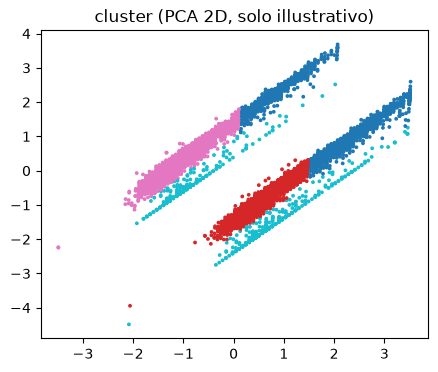

In [5]:
cand = bw[bw.n_feats >= 3].sort_values("score", ascending=False).iloc[0]
SEL_FEATURES = list(cand.features); K_FINAL = int(cand.k)
# --- sovrascrivi qui per scegliere a mano ---
# SEL_FEATURES = ["qrs_duration", "age_at_ecg", "ventricular_rate"]; K_FINAL = 4
print("Feature per il clustering:", SEL_FEATURES, "| k =", K_FINAL)

need_wave = any(f in WAVE_NAMES for f in SEL_FEATURES)
imp2, sc2 = SimpleImputer(strategy="median"), StandardScaler()
Zsel = np.clip(sc2.fit_transform(imp2.fit_transform(F_pool[SEL_FEATURES])), -4, 4)
km_final = KMeans(K_FINAL, n_init=10, random_state=SEED).fit(Zsel)

def assign(df, split_name):
    F = feature_frame(df, split_name, need_wave)[SEL_FEATURES]
    return km_final.predict(np.clip(sc2.transform(imp2.transform(F)), -4, 4))
for d, s in [(train, "train"), (val, "val"), (test, "test")]:
    d["cluster"] = assign(d, s) if (d is not test or RUN_FINAL_TEST) else -1
print("dimensione cluster (train):", train.cluster.value_counts().sort_index().to_dict())

# visualizzazione 2D (solo illustrativa: PCA sulle feature selezionate)
from sklearn.decomposition import PCA
pc = PCA(2).fit_transform(Zsel)
plt.figure(figsize=(5, 4)); plt.scatter(pc[:, 0], pc[:, 1], c=km_final.labels_, s=3, cmap="tab10"); plt.title("cluster (PCA 2D, solo illustrativo)"); plt.show()

## 5 · I cluster differiscono per l'esito?

Profilo medio delle feature e prevalenza di ogni condizione per cluster. Un test chi-quadro sul target dice se la prevalenza varia tra cluster. Se non varia, i cluster non isolano gruppi con rischio diverso.

,sex,ventricular_rate,atrial_rate,pr_interval,qrs_duration,qt_corrected,age_at_ecg,n_train,prev_target_train,prev_target_val
cluster,,,,,,,,,,
0,0.68,81.19,81.09,175.69,140.10,488.32,67.12,9363,0.735,0.705
1,1.00,83.49,83.39,160.25,90.45,446.03,59.67,31035,0.528,0.437
2,0.00,82.89,82.92,154.51,84.85,448.62,60.52,29655,0.432,0.336
3,0.64,96.36,288.18,165.67,97.55,455.85,68.35,2422,0.779,0.667


chi-quadro prevalenza shd_moderate_or_greater_flag tra cluster (train): p = 0


cluster,0,1,2,3
shd_moderate_or_greater_flag,0.735,0.528,0.432,0.779
lvef_lte_45_flag,0.456,0.238,0.149,0.366
lvwt_gte_13_flag,0.357,0.272,0.167,0.372
aortic_stenosis_moderate_or_greater_flag,0.081,0.032,0.035,0.062
aortic_regurgitation_moderate_or_greater_flag,0.020,0.012,0.009,0.023
mitral_regurgitation_moderate_or_greater_flag,0.164,0.062,0.075,0.192
tricuspid_regurgitation_moderate_or_greater_flag,0.166,0.075,0.108,0.259
pulmonary_regurgitation_moderate_or_greater_flag,0.015,0.007,0.006,0.021
rv_systolic_dysfunction_moderate_or_greater_flag,0.243,0.126,0.093,0.279
pericardial_effusion_moderate_large_flag,0.026,0.034,0.021,0.065


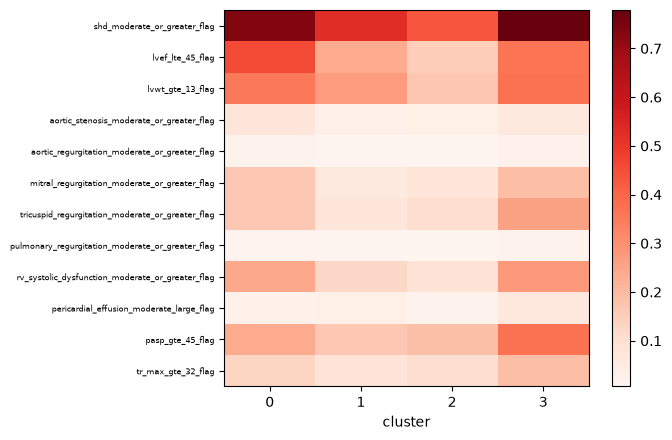

In [6]:
prof = train.groupby("cluster")[ECG_FEATURES].mean().round(2); prof["n_train"] = train.groupby("cluster").size()
prof["prev_target_train"] = train.groupby("cluster")[TARGET].mean().round(3); prof["prev_target_val"] = val.groupby("cluster")[TARGET].mean().round(3)
display(prof)
ct = pd.crosstab(train.dropna(subset=[TARGET]).cluster, train.dropna(subset=[TARGET])[TARGET])
chi2, pval, *_ = stats.chi2_contingency(ct); print(f"chi-quadro prevalenza {TARGET} tra cluster (train): p = {pval:.2g}")
flag_prev = train.groupby("cluster")[FLAG_COLS].mean().T.round(3); display(flag_prev)
fig, ax = plt.subplots(figsize=(7, 4.5)); im = ax.imshow(flag_prev.values, aspect="auto", cmap="Reds")
ax.set_yticks(range(len(flag_prev))); ax.set_yticklabels(flag_prev.index, fontsize=6); ax.set_xticks(range(flag_prev.shape[1])); ax.set_xlabel("cluster")
plt.colorbar(im); plt.tight_layout(); plt.show()

## 6 · Predizione dentro ogni cluster (il test che conta)

Per ogni cluster con abbastanza positivi:
- **modello globale**: addestrato su tutto il train, valutato sui pazienti di validation di quel cluster;
- **modelli locali**: addestrati solo sul train del cluster (regressione logistica, Lasso, boosting);
- **locale con selezione feature**: eliminazione all'indietro delle feature predittive con CV raggruppata per paziente *dentro il solo train del cluster*, scegliendo il sottoinsieme più piccolo entro 0.003 AUROC dal migliore.

Il confronto equo è `AUROC_globale` contro `AUROC_locale_*` **sugli stessi pazienti di validation**.

,cluster,n_train,n_val,prev_val,AUROC_globale,glob_lo,glob_hi,AUROC_locale_logreg,AUROC_locale_lasso_logreg,AUROC_locale_hist_gb,AUROC_locale_feat_sel,loc_lo,loc_hi,feature_selezionate
0,0,9363,563,0.705,0.750,0.709,0.790,0.736,0.736,0.740,0.718,0.674,0.756,"pr_interval, qt_corrected"
1,1,31035,1824,0.437,0.702,0.679,0.723,0.697,0.697,0.692,0.697,0.673,0.719,"ventricular_rate, pr_interval, qrs_duration, q..."
2,2,29655,2104,0.336,0.722,0.699,0.744,0.715,0.715,0.723,0.715,0.691,0.738,"ventricular_rate, pr_interval, qrs_duration, q..."
3,3,2422,135,0.667,0.651,0.566,0.741,0.684,0.686,0.627,0.674,0.596,0.760,"ventricular_rate, atrial_rate, pr_interval, qr..."


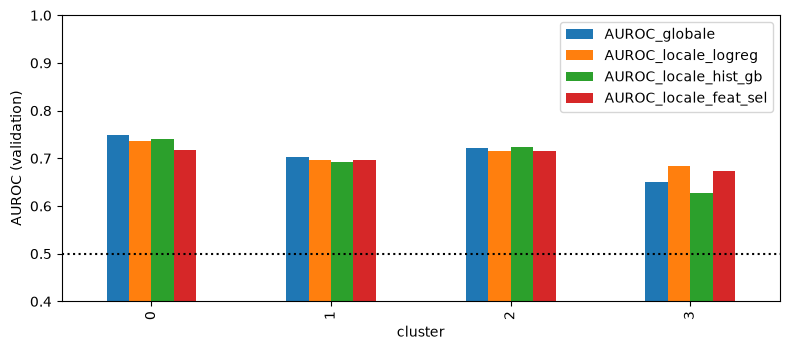

In [7]:
MIN_POS_TRAIN, MIN_POS_VAL = 60, 20
Xtr_all, ytr_all, dtr = get_xy(train, PRED_TARGET, PRED_FEATURES); Xva_all, yva_all, dva = get_xy(val, PRED_TARGET, PRED_FEATURES)
glob = model_zoo()["hist_gb"].fit(Xtr_all, ytr_all); pg = glob.predict_proba(Xva_all)[:, 1]

def backward_predictive(Xc, yc, groups, feats, tol=0.003):
    cols = list(feats)
    def cv_auc(cs): return safe_auc(yc, oof_proba(model_zoo()["logreg"], Xc[cs], yc, groups, n_splits=4))
    path = [(len(cols), cv_auc(cols), list(cols))]
    while len(cols) > 1:
        s, c = max((cv_auc([x for x in cols if x != c]), c) for c in cols)
        cols.remove(c); path.append((len(cols), s, list(cols)))
    best = max(p[1] for p in path)
    return sorted([p for p in path if p[1] >= best - tol], key=lambda p: p[0])[0][2], path

def eligible(c):
    mt, mv = (dtr.cluster == c).values, (dva.cluster == c).values
    ok = ytr_all[mt].sum() >= MIN_POS_TRAIN and yva_all[mv].sum() >= MIN_POS_VAL and (mv.sum() - yva_all[mv].sum()) >= MIN_POS_VAL
    return ok, mt, mv

res, final_models = [], {}
for c in sorted(train.cluster.unique()):
    ok, mt, mv = eligible(c)
    if not ok: print(f"cluster {c}: saltato (positivi insufficienti)"); continue
    a, lo, hi = fmt_auc(yva_all[mv], pg[mv])
    row = dict(cluster=c, n_train=int(mt.sum()), n_val=int(mv.sum()), prev_val=yva_all[mv].mean(), AUROC_globale=a, glob_lo=lo, glob_hi=hi)
    for name in ("logreg", "lasso_logreg", "hist_gb"):
        m = model_zoo()[name].fit(Xtr_all[mt], ytr_all[mt]); row[f"AUROC_locale_{name}"] = safe_auc(yva_all[mv], m.predict_proba(Xva_all[mv])[:, 1])
    sel, _ = backward_predictive(Xtr_all[mt], ytr_all[mt], dtr.patient_key.values[mt], PRED_FEATURES)
    m = model_zoo()["logreg"].fit(Xtr_all[mt][sel], ytr_all[mt])
    a2, lo2, hi2 = fmt_auc(yva_all[mv], m.predict_proba(Xva_all[mv][sel])[:, 1])
    row.update(AUROC_locale_feat_sel=a2, loc_lo=lo2, loc_hi=hi2, feature_selezionate=", ".join(sel))
    final_models[c] = (sel, m); res.append(row)
cl_res = pd.DataFrame(res); cl_res.to_csv(OUT_DIR / "03_predizione_per_cluster.csv", index=False); display(cl_res.round(3))
if len(cl_res):
    cl_res.set_index("cluster")[["AUROC_globale", "AUROC_locale_logreg", "AUROC_locale_hist_gb", "AUROC_locale_feat_sel"]].plot.bar(figsize=(8, 3.6))
    plt.axhline(0.5, color="k", ls=":"); plt.ylim(0.4, 1); plt.ylabel("AUROC (validation)"); plt.tight_layout(); plt.show()

**Come leggere.** Un cluster è interessante se `AUROC_locale_*` supera `AUROC_globale` con intervalli di confidenza separati *e* se il vantaggio ha un senso clinico (per esempio un cluster con QRS largo). Se i valori locali sono simili al globale, i cluster non aiutano. Se un cluster mostra AUROC alto perché ha una prevalenza molto diversa dalle altre, controlla anche AUPRC e la calibrazione prima di presentarlo.

## 7 · Soglia di rumore: il miglior cluster batte il caso?

Mescolando a caso le etichette (train e validation) si rompe ogni relazione tra feature ed esito. Si rifà la stessa analisi per cluster e si registra il **massimo** AUROC tra i cluster. Ripetendo, si ottiene la distribuzione di "quanto bene sembra funzionare il cluster migliore per solo effetto del caso". Il valore osservato va confrontato con quella distribuzione.

AUROC massimo tra cluster con etichette mescolate: media=0.529, 95° percentile=0.575
AUROC massimo osservato (logreg locale): 0.736  -> p empirico = 0.032


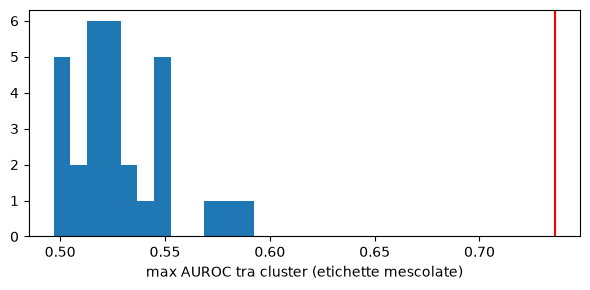

In [8]:
N_PERM = 30
elig = [c for c in sorted(train.cluster.unique()) if eligible(c)[0]]
rg = np.random.default_rng(123)
null_max = []
for _ in range(N_PERM):
    yt, yv = ytr_all.copy(), yva_all.copy(); rg.shuffle(yt); rg.shuffle(yv)
    aucs = []
    for c in elig:
        _, mt, mv = eligible(c)
        m = model_zoo()["logreg"].fit(Xtr_all[mt], yt[mt]); aucs.append(safe_auc(yv[mv], m.predict_proba(Xva_all[mv])[:, 1]))
    null_max.append(np.nanmax(aucs))
null_max = np.array(null_max)
obs = cl_res["AUROC_locale_logreg"].max() if len(cl_res) else np.nan
print(f"AUROC massimo tra cluster con etichette mescolate: media={null_max.mean():.3f}, 95° percentile={np.percentile(null_max, 95):.3f}")
print(f"AUROC massimo osservato (logreg locale): {obs:.3f}  -> p empirico = {(1 + (null_max >= obs).sum()) / (1 + N_PERM):.3f}")
plt.figure(figsize=(6, 3)); plt.hist(null_max, bins=12); plt.axvline(obs, color="r"); plt.xlabel("max AUROC tra cluster (etichette mescolate)"); plt.tight_layout(); plt.show()

## 8 · Valutazione finale su test (una sola volta)

Impostare `RUN_FINAL_TEST = True` nella cella di setup **e rieseguire dall'inizio**, solo quando feature, `k` e modelli sono definitivi. La cella sotto applica a test i cluster e i modelli locali già addestrati, e confronta con il modello globale sugli stessi pazienti.

In [10]:
if RUN_FINAL_TEST:
    test["cluster"] = assign(test, "test")
    Xte, yte, dte = get_xy(test, PRED_TARGET, PRED_FEATURES); pt = glob.predict_proba(Xte)[:, 1]
    out = []
    for c, (sel, m) in final_models.items():
        mk = (dte.cluster == c).values
        if mk.sum() < 50 or len(np.unique(yte[mk])) < 2: continue
        out.append(dict(cluster=c, n_test=int(mk.sum()), prev_test=yte[mk].mean(), AUROC_globale=safe_auc(yte[mk], pt[mk]),
                        AUROC_locale=safe_auc(yte[mk], m.predict_proba(Xte[mk][sel])[:, 1]), feature=", ".join(sel)))
    display(pd.DataFrame(out).round(3))
else:
    print("RUN_FINAL_TEST=False: test non toccato.")

,cluster,n_test,prev_test,AUROC_globale,AUROC_locale,feature
0,0,655,0.708,0.734,0.714,"pr_interval, qt_corrected"
1,1,2194,0.425,0.732,0.718,"ventricular_rate, pr_interval, qrs_duration, q..."
2,2,2419,0.330,0.735,0.725,"ventricular_rate, pr_interval, qrs_duration, q..."
3,3,174,0.707,0.574,0.573,"ventricular_rate, atrial_rate, pr_interval, qr..."
